In [ ]:
# 04 expression — Wang 2019 GBM. EMT-TF overlay (categorical thresholded expressers on grey manifold).
# Unconditional final notebook. Reads processed.h5ad; uses the linear layout + pseudotime from signatures.
import os, sys, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1; SEED = 1; np.random.seed(SEED)

In [ ]:
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6)); pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

In [ ]:
# spec: expression reads processed.h5ad. Pull the linear layout + pseudotime from signatures.h5ad
# (same cells, one connected component) so the panel matches the trajectory orientation.
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
sig = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata = adata[sig.obs_names].copy()
adata.obsm['X_umap'] = sig.obsm['X_umap_lin']     # house linear layout
adata.obs['t'] = sig.obs['t'].values
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime range', round(t.min(),2), '->', round(t.max(),2))

cells: 9634 | pseudotime range 0.0 -> 12.26


In [ ]:
# EMT-TF candidate panel — Snail/Zeb/Twist PLUS other mesenchymal families (FOXC, PRRX, TCF, SOX9, RUNX2).
# VIM is a mesenchymal MARKER, not a TF -> excluded. Score each on detectable expression + pseudotime trend.
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2','TCF3','TCF4','SOX9','RUNX2','GATA3']
present = [g for g in dict.fromkeys(panel) if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j, g in enumerate(present):
    x = X[:,j]; rho, p = spearmanr(tn, x)
    rows.append((g, round((x>0).mean(),3), round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t'])
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(root)', 'LATE(terminus)')
df = df.sort_values('rho_vs_t')
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03]
print('\ndetectable TFs (frac>0.03):', ok.TF.tolist())

    TF  frac_expr  mean_early  mean_late  rho_vs_t            end
  TCF4      0.881       2.022      1.503    -0.239    EARLY(root)
  ZEB1      0.699       1.374      0.840    -0.238    EARLY(root)
  ZEB2      0.670       1.082      0.746    -0.159    EARLY(root)
TWIST1      0.043       0.040      0.028    -0.079    EARLY(root)
  TCF3      0.252       0.180      0.151    -0.075    EARLY(root)
 GATA3      0.005       0.005      0.001    -0.055    EARLY(root)
 SNAI1      0.006       0.003      0.004     0.001 LATE(terminus)
TWIST2      0.003       0.002      0.003     0.008 LATE(terminus)
 FOXC2      0.001       0.000      0.001     0.010 LATE(terminus)
 PRRX2      0.005       0.001      0.006     0.022 LATE(terminus)
 SNAI2      0.016       0.004      0.012     0.039 LATE(terminus)
 FOXC1      0.006       0.000      0.007     0.061 LATE(terminus)
  SOX9      0.186       0.122      0.217     0.061 LATE(terminus)
 RUNX2      0.085       0.044      0.094     0.075 LATE(terminus)
 PRRX1    

In [ ]:
# pick the most informative expresser at each end: root-enriched vs terminus-enriched (canonical EMT-TFs
# preferred over near-ubiquitous general factors). ZEB1 (root/early) and PRRX1 (terminus/late) are the pair.
EARLY_TF = 'ZEB1'; LATE_TF = 'PRRX1'
def _vec(g):
    x = adata[:,g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in [EARLY_TF, LATE_TF]:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in [EARLY_TF, LATE_TF]}
print('overlay thresholds (upper quartile among expressers):', {g: round(thr[g],2) for g in [EARLY_TF,LATE_TF]})
print('cells shown:', {g: int(sel[g].sum()) for g in [EARLY_TF, LATE_TF]})
for g in [EARLY_TF, LATE_TF]:
    m = sel[g]
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; mean pseudotime of shown cells = {tn[m].mean():.2f} (all = {tn.mean():.2f})')

overlay thresholds (upper quartile among expressers): {'ZEB1': 2.09, 'PRRX1': 1.41}
cells shown: {'ZEB1': 1683, 'PRRX1': 959}
ZEB1: 69.9% expressing; mean pseudotime of shown cells = 0.30 (all = 0.47)
PRRX1: 39.8% expressing; mean pseudotime of shown cells = 0.69 (all = 0.47)


saved expression.pdf


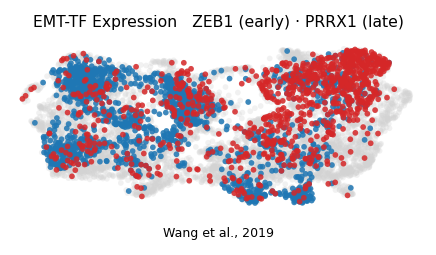

In [ ]:
# expression.pdf — categorical thresholded overlay of two EMT-TFs on a grey manifold (house aspect)
xl = adata.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo, yhi = np.percentile(xl[:,1],[0.3,99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
order = sorted([EARLY_TF, LATE_TF], key=lambda g: -int(sel[g].sum()))
colors = {EARLY_TF:'tab:blue', LATE_TF:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.85, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title(f'EMT-TF Expression   {EARLY_TF} (early) · {LATE_TF} (late)', size=7.5)
ax.text(.5, -.14, 'Wang et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight'); plt.show()
print('saved expression.pdf')